In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Os arquivos do dataset estão localizados na pasta `/content/drive/MyDrive/TDE 01 - IA/`.

### Inicialização do Ambiente do Projeto

In [10]:
import pandas as pd
import numpy as np

# Definição do caminho do dataset conforme configurado no ambiente
caminho_transaction = '/content/drive/MyDrive/TDE 01 - IA/train_transaction.csv'

# Carregando o dataset
try:
    df = pd.read_csv(caminho_transaction)
    print(f"Dataset carregado com sucesso!")
    print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas.")

    # Verificar a distribuição da variável alvo (isFraud)
    print("\nDistribuição da variável alvo (isFraud):")
    dist = df['isFraud'].value_counts(normalize=True) * 100
    for classe, porc in dist.items():
        print(f"  Classe {classe}: {porc:.2f}%")

except Exception as e:
    print(f"Erro ao carregar o dataset: {e}")

Dataset carregado com sucesso!
Dimensões do dataset: 590540 linhas e 394 colunas.

Distribuição da variável alvo (isFraud):
  Classe 0: 96.50%
  Classe 1: 3.50%


Caso precise instalar dependências de PDF para documentação auxiliar:

In [11]:
!pip install PyMuPDF

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.0/69.0 MB 49.3 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 48.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [PyMuPDF]


# TDE 04 — Evolução e Comparação de Modelos de Machine Learning para Detecção de Fraudes

## 1. Contextualização e Objetivo

A detecção de fraudes em transações financeiras é um dos principais desafios enfrentados por instituições de tecnologia financeira (*fintechs*) e operadoras de cartões de crédito. A ocorrência de atividades fraudulentas resulta em prejuízos bilionários anualmente, além de afetar negativamente a confiança dos consumidores no ecossistema de pagamentos eletrônicos.

### O Dataset e a Variável-Alvo
Neste projeto, utilizamos o conjunto de dados reais de transações eletrônicas fornecido pela **Vesta Corporation** (originalmente disponibilizado na competição da IEEE-CIS no Kaggle). Nosso objetivo é modelar a detecção de fraudes como um problema clássico de **classificação binária supervisionada**:
*   **`isFraud = 0`**: Transação legítima.
*   **`isFraud = 1`**: Transação fraudulenta.

### Objetivos do TDE 04
A partir das análises iniciais da base (TDE 01) e da implementação dos modelos *baseline* de Árvore de Decisão e Floresta Aleatória (TDE 03), o presente trabalho tem como objetivos:

1. **Aprofundar a modelagem preditiva** por meio da implementação de Support Vector Machines (SVM) com kernels Linear e RBF e Redes Neurais Multicamadas (MLP).
2. **Explorar novos algoritmos de classificação** não abordados em sala de aula, como XGBoost e LightGBM, ambos baseados em *Gradient Boosting*.
3. **Avaliar e comparar o desempenho dos modelos**, considerando o pré-processamento dos dados e o desbalanceamento das classes, utilizando métricas como `Acurácia Balanceada`, `Recall`, `Precision`, `F1-Score` e `ROC-AUC`.
4. **Otimizar e definir o modelo final** por meio da validação cruzada e do ajuste de hiperparâmetros, justificando sua escolha com base nos resultados experimentais.


## 2. Resumo dos Resultados do TDE 01

No primeiro trabalho de engenharia de dados e análise exploratória (**TDE 01**), foram realizadas análises aprofundadas sobre a qualidade e estrutura do conjunto de dados de transações da Vesta Corporation. Os principais pontos identificados e tratados foram:

### 1. Limpeza de Dados e Valores Ausentes
*   O dataset original possui **394 colunas** e mais de **590 mil registros**.
*   Identificamos que uma vasta quantidade de colunas continha uma proporção extrema de valores faltantes (nulos). Para preservar a qualidade preditiva, aplicamos um filtro descartando todas as colunas com **mais de 50% de valores nulos**.

### 2. Desbalanceamento Crítico de Classes
*   Como é típico em cenários de detecção de fraudes, a nossa variável-alvo `isFraud` é **extremamente desbalanceada**.
*   Aproximadamente **96,50%** das transações da base são legítimas (`isFraud = 0`), contra apenas **3,50%** de transações fraudulentas (`isFraud = 1`).
*   Esse desbalanceamento severo exige o uso de métricas alternativas de avaliação (como *Recall*, *F1-Score* e *ROC-AUC*) no lugar da acurácia simples, que seria facilmente inflacionada por um classificador ingênuo.

Vamos visualizar a distribuição real dessas classes abaixo para fundamentar essa característica crítica do problema.

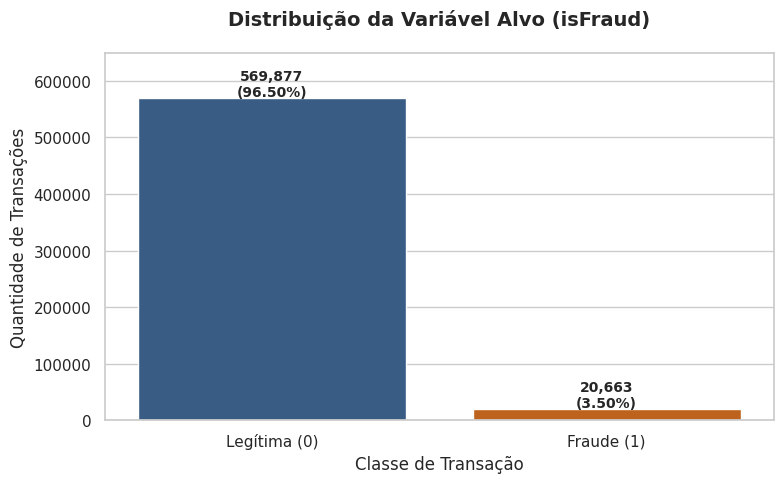

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração estética dos plots
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))

# Contagem de classes na variável original carregada
contagem_classes = df['isFraud'].value_counts()
percentuais = df['isFraud'].value_counts(normalize=True) * 100

# Criando o gráfico de barras
cores = ['#2b5c8f', '#d95f02']
barras = sns.barplot(x=contagem_classes.index, y=contagem_classes.values, palette=cores, hue=contagem_classes.index, legend=False, ax=ax)

# Adicionando rótulos com valores absolutos e percentuais sobre as barras
for i, p in enumerate(barras.patches):
    valor = contagem_classes.values[i]
    percentual = percentuais.values[i]
    ax.annotate(f'{valor:,}\n({percentual:.2f}%)',
                (p.get_x() + p.get_width() / 2., p.get_height() + 5000),
                ha='center', va='center', xytext=(0, 8),
                textcoords='offset points', fontsize=10, fontweight='bold')

# Título e labels estruturados
plt.title('Distribuição da Variável Alvo (isFraud)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Classe de Transação', fontsize=12)
plt.ylabel('Quantidade de Transações', fontsize=12)
plt.xticks([0, 1], ['Legítima (0)', 'Fraude (1)'], fontsize=11)
plt.ylim(0, df.shape[0] * 1.1)  # margem no topo do plot

plt.tight_layout()
plt.show()

## 3. Resumo dos Modelos e Resultados do TDE 03

No trabalho anterior (**TDE 03**), estabelecemos nossos modelos de referência (*baselines*) utilizando algoritmos clássicos baseados em árvores sobre uma amostra estratificada de 10% do conjunto de dados original:

### 1. Árvore de Decisão (`DecisionTreeClassifier`)
*   **Conceito**: Um classificador não paramétrico que particiona o espaço amostral de maneira recursiva com base nos atributos mais discriminativos (critério Gini/Entropia).
*   **Limitações**: Apresenta comportamento instável (alta variância) frente a pequenas alterações na base e tende a construir regras excessivamente complexas se não houver pós-poda ou controle de profundidade máxima.

### 2. Floresta Aleatória (`RandomForestClassifier`)
*   **Conceito**: Um método de aprendizado conjunto (*Ensemble Bagging*) que treina múltiplos estimadores fracos (árvores) em paralelo, utilizando amostragem com reposição (*Bootstrap*) e seleção aleatória de subconjuntos de recursos, consolidando as previsões por voto majoritário.
*   **Limitações**: Elevado custo de processamento e alocação de memória ao lidar com um número massivo de árvores sobre grandes volumes de dados. Adicionalmente, sob forte desbalanceamento de classes, o algoritmo pode ser enviesado em direção à classe majoritária se não houver penalização customizada.

In [13]:
# Tabela Comparativa de Desempenho extraída diretamente do TDE 03
import pandas as pd

resultados_tde03 = {
    'Modelo Baseline': ['Árvore de Decisão', 'Floresta Aleatória'],
    'Acurácia Balanceada': [0.6092, 0.5639],
    'ROC AUC': [0.6092, 0.7982], # Corrigida a inversão: Árvore = 0.6092, Floresta = 0.7982
    'Acurácia': [0.9462, 0.9667],
    'Precisão': [0.2389, 0.6136],
    'Recall': [0.2470, 0.1308],
    'F1-Score': [0.2429, 0.2156]
}

df_resultados_tde03 = pd.DataFrame(resultados_tde03)

# Exibição estilizada usando Pandas Styler
styled_df = df_resultados_tde03.style.format({
    'Acurácia Balanceada': '{:.4f}',
    'ROC AUC': '{:.4f}',
    'Acurácia': '{:.4f}',
    'Precisão': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}'
}).set_properties(**{
    'border-color': 'lightgrey',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2b5c8f'), ('color', 'white'), ('font-weight', 'bold')]}
])

# Exibir DataFrame formatado
styled_df

,Modelo Baseline,Acurácia Balanceada,ROC AUC,Acurácia,Precisão,Recall,F1-Score
0,Árvore de Decisão,0.6092,0.6092,0.9462,0.2389,0.2470,0.2429
1,Floresta Aleatória,0.5639,0.7982,0.9667,0.6136,0.1308,0.2156


### Discussão dos Resultados (TDE 03)

Ao comparar os desempenhos obtidos pelos modelos baseline, observamos os seguintes comportamentos fundamentais:

1. **Acurácia Tradicional vs. Métricas Robustas**:
   * Embora ambos os modelos apresentem métricas de Acurácia global aparentemente excelentes (94,62% para Árvore e 96,67% para Floresta), esse resultado é ilusório. Devido ao desbalanceamento extremo de classes (~3,5% de fraudes), um classificador ingênuo que simplesmente rotulasse todas as instâncias como "legítimas" alcançaria aproximadamente 96,5% de acurácia.
   * A **Acurácia Balanceada** (0,6092 para a Árvore de Decisão e 0,5639 para a Floresta Aleatória) revela o verdadeiro cenário: os modelos encontram severas dificuldades para distinguir transações fraudulentas de legítimas.

2. **O Trade-off de Desempenho entre os Baselines**:
   * **Árvore de Decisão**: Apresentou um **Recall** superior para a classe minoritária (`0.2470` contra `0.1308` da Floresta). No entanto, sua **Precisão** foi extremamente baixa (`0.2389`), resultando em uma alta taxa de falsos positivos (transações legítimas erroneamente classificadas como fraude).
   * **Floresta Aleatória**: Obteve uma melhoria expressiva em **Precisão** (`0.6136`), minimizando falsos positivos. Entretanto, seu **Recall** despencou para `0.1308`, deixando passar a grande maioria das fraudes reais (falsos negativos).
   * O **ROC-AUC** do RandomForest (`0.7982` vs `0.6092` da Árvore) evidencia que a Floresta Aleatória possui maior capacidade de separação probabilística entre as classes, mas o ponto de corte padrão (0.50) adotado pelo modelo sem ajustes é ineficaz sob desbalanceamento severo.

3. **Motivação para o TDE 04**:
   * Estes resultados demonstram de forma inequívoca que a avaliação de modelos sob desbalanceamento severo é altamente sensível, motivando a investigação de estratégias adicionais de balanceamento ou otimização de limiares de decisão.
   * Esta lacuna incentiva a introdução e o teste de novas abordagens neste **TDE 04**, como algoritmos robustos a fronteiras de decisão não-lineares (**SVM**), mapeamento denso de características por redes neurais (**MLP**) e algoritmos baseados em Boosting (**XGBoost** e **LightGBM**), complementados pelo estudo de técnicas de balanceamento de classes e refinamento de hiperparâmetros.

## 4. Carregamento e Preparação dos Dados

Nesta etapa, estruturamos um pipeline de preparação de dados robusto e livre de vazamento de dados (*data leakage*), garantindo a consistência com as etapas realizadas no TDE 03, porém aplicando as transformações de maneira metodologicamente correta:

1. **Amostragem Estratificada**: Mantemos uma amostra inicial de 10% do dataset original (`random_state=42`) para viabilidade computacional no Colab.
2. **Divisão Precoce entre Treino (80%) e Teste (20%)**: Realizada imediatamente após a amostragem e antes de qualquer análise de nulos ou pré-processamento, blindando o conjunto de teste.
3. **Filtro de Valores Ausentes (> 50%)**: Identificação e eliminação de atributos com mais de 50% de valores nulos utilizando **apenas o conjunto de treinamento** como referência.
4. **Imputação e Codificação via Pipeline**: Utilização do `ColumnTransformer` e `Pipeline` do Scikit-learn para imputar valores numéricos pela mediana (calculada estritamente no treino), preencher categóricos nulos com `'Missing'`, e aplicar One-Hot Encoding de forma consistente.
5. **Padronização**: Configuração do `StandardScaler` ajustado apenas no treino.
6. **Disponibilização de Dados**: Geração de partições finais padronizadas (essenciais para SVM e MLP) e não padronizadas (ideais para XGBoost e LightGBM), mantendo o conjunto de teste isolado para a avaliação final.

In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from google.colab import drive

# Definição do caminho do dataset conforme configurado no ambiente
caminho_transaction = '/content/drive/MyDrive/TDE 01 - IA/train_transaction.csv'

# Carrega o Drive e o dataset de forma resiliente se o kernel tiver sido reiniciado
if 'df' not in globals() and 'df' not in locals():
    print("Garantindo a montagem do Google Drive...")
    try:
        drive.mount('/content/drive', force_remount=True)
    except Exception as e:
        print(f"Aviso na montagem: {e}")

    print("Carregando dataset do Google Drive...")
    df = pd.read_csv(caminho_transaction)
    print("Dataset carregado com sucesso!")

# 1. Separar variáveis explicativas (X) da variável-alvo (y)
cols_explicativas = [col for col in df.columns if col not in ['TransactionID', 'isFraud']]
X = df[cols_explicativas].copy()
y = df['isFraud'].copy()

# 2. Amostragem Estratificada de 10% para viabilizar o processamento no Colab
_, X_sample, _, y_sample = train_test_split(
    X, y,
    test_size=0.10,
    stratify=y,
    random_state=42
)

# 3. Divisão Estratificada imediata em Treino (80%) e Teste (20%) antes do pré-processamento
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_sample, y_sample,
    test_size=0.20,
    stratify=y_sample,
    random_state=42
)

print(f"Amostra 10% total: {X_sample.shape[0]} registros.")
print(f"Conjunto de Treino Bruto (Raw): {X_train_raw.shape[0]} registros.")
print(f"Conjunto de Teste Bruto (Raw): {X_test_raw.shape[0]} registros.")

Amostra 10% total: 59054 registros.
Conjunto de Treino Bruto (Raw): 47243 registros.
Conjunto de Teste Bruto (Raw): 11811 registros.


In [15]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 4. Determinar colunas com mais de 50% de nulos usando APENAS o conjunto de treinamento
limite_nulos = 0.50 * len(X_train_raw)
colunas_para_remover = X_train_raw.columns[X_train_raw.isnull().sum() > limite_nulos].tolist()

print(f"Colunas identificadas para remoção (>50% nulos no treino): {len(colunas_para_remover)}")

# Aplicando a remoção de colunas em ambos os conjuntos de forma independente
X_train_filtered = X_train_raw.drop(columns=colunas_para_remover)
X_test_filtered = X_test_raw.drop(columns=colunas_para_remover)

# 5. Separar colunas numéricas e categóricas restantes do conjunto filtrado
cols_numericas = X_train_filtered.select_dtypes(include=[np.number]).columns.tolist()
cols_categoricas = X_train_filtered.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Variáveis Numéricas para processar: {len(cols_numericas)}")
print(f"Variáveis Categóricas para processar: {len(cols_categoricas)}")

Colunas identificadas para remoção (>50% nulos no treino): 174
Variáveis Numéricas para processar: 209
Variáveis Categóricas para processar: 9


In [16]:
# 6. Construção do Pipeline de Pré-processamento com Scikit-Learn

# Pipeline para variáveis numéricas: Imputação por Mediana
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Pipeline para variáveis categóricas: Imputação com 'Missing' e One-Hot Encoding
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# ColumnTransformer para combinar os processamentos das colunas
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, cols_numericas),
    ('cat', cat_transformer, cols_categoricas)
])

# 7. Ajustar e aplicar o pré-processamento exclusivamente no Treino
# (Isso garante que as medianas e categorias conhecidas venham apenas do treino)
X_train_processed = preprocessor.fit_transform(X_train_filtered)
X_test_processed = preprocessor.transform(X_test_filtered)

# Obter nomes das colunas após o processamento (opcional, útil para análise)
feature_names = (
    cols_numericas +
    list(preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cols_categoricas))
)

# 8. Criar versão padronizada usando StandardScaler ajustado apenas no Treino
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_processed)
X_test_scaled = scaler.transform(X_test_processed)

print("Pré-processamento e divisão concluídos com absoluto isolamento de dados!")
print(f"Quantidade final de features após One-Hot Encoding: {len(feature_names)}")
print(f"X_train_processed (Não Padronizado): {X_train_processed.shape}")
print(f"X_train_scaled (Padronizado): {X_train_scaled.shape}")
print(f"X_test_processed (Não Padronizado): {X_test_processed.shape}")
print(f"X_test_scaled (Padronizado): {X_test_scaled.shape}")

Pré-processamento e divisão concluídos com absoluto isolamento de dados!
Quantidade final de features após One-Hot Encoding: 300
X_train_processed (Não Padronizado): (47243, 300)
X_train_scaled (Padronizado): (47243, 300)
X_test_processed (Não Padronizado): (11811, 300)
X_test_scaled (Padronizado): (11811, 300)


## 5. Implementação dos Modelos Baseline com Validação Cruzada

Nesta seção, restabelecemos as nossas referências do TDE 03 aplicando validação cruzada estratificada com 3 folds exclusivamente sobre o conjunto de treinamento.

Para garantir a conformidade metodológica e evitar o vazamento de dados, integramos o transformador de pré-processamento (`preprocessor`) desenvolvido no Tópico 4 dentro de um `Pipeline` do Scikit-learn para cada modelo. Assim, todas as etapas de imputação, codificação categórica e filtragem de variáveis são ajustadas apenas no subconjunto de treino de cada fold. Avaliamos os classificadores com base nas médias de seis métricas chave, mantendo o conjunto de teste isolado para a validação final do projeto.

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
import pandas as pd

# 1. Definir a estratégia de validação cruzada (3 folds estratificados)
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 2. Definir os estimadores básicos com parâmetros padrão consistentes
model_dt = DecisionTreeClassifier(random_state=42)
model_rf = RandomForestClassifier(random_state=42, n_jobs=-1)

# 3. Criar Pipelines integrando o pré-processador do Tópico 4 a cada modelo
# Note que usamos os dados não padronizados na entrada, pois as árvores de decisão não exigem padronização.
pipeline_dt = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', model_dt)
])

pipeline_rf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', model_rf)
])

# Dicionário de métricas requisitado
scoring_metrics = {
    'balanced_accuracy': 'balanced_accuracy',
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

print("Executando Validação Cruzada de 3 Folds para a Árvore de Decisão...")
cv_results_dt = cross_validate(
    pipeline_dt, X_train_filtered, y_train,
    cv=cv_strategy, scoring=scoring_metrics, n_jobs=-1
)

print("Executando Validação Cruzada de 3 Folds para a Floresta Aleatória...")
cv_results_rf = cross_validate(
    pipeline_rf, X_train_filtered, y_train,
    cv=cv_strategy, scoring=scoring_metrics, n_jobs=-1
)

print("Validação cruzada concluída com sucesso!")

Executando Validação Cruzada de 3 Folds para a Árvore de Decisão...
Executando Validação Cruzada de 3 Folds para a Floresta Aleatória...
Validação cruzada concluída com sucesso!


In [18]:
# 4. Consolidar a média das métricas de validação cruzada
resultados_cv = []

for nome, resultados in [('Árvore de Decisão', cv_results_dt), ('Floresta Aleatória', cv_results_rf)]:
    resultados_cv.append({
        'Modelo Baseline (CV)': nome,
        'Acurácia Balanceada': resultados['test_balanced_accuracy'].mean(),
        'ROC AUC': resultados['test_roc_auc'].mean(),
        'Acurácia': resultados['test_accuracy'].mean(),
        'Precisão': resultados['test_precision'].mean(),
        'Recall': resultados['test_recall'].mean(),
        'F1-Score': resultados['test_f1'].mean()
    })

df_resultados_cv = pd.DataFrame(resultados_cv)

# Exibição da tabela de resultados com a formatação original
styled_resultados_cv = df_resultados_cv.style.format({
    'Acurácia Balanceada': '{:.4f}',
    'ROC AUC': '{:.4f}',
    'Acurácia': '{:.4f}',
    'Precisão': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}'
}).set_properties(**{
    'border-color': 'lightgrey',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2b5c8f'), ('color', 'white'), ('font-weight', 'bold')]}
])

styled_resultados_cv

,Modelo Baseline (CV),Acurácia Balanceada,ROC AUC,Acurácia,Precisão,Recall,F1-Score
0,Árvore de Decisão,0.6706,0.6706,0.9517,0.3294,0.3684,0.3477
1,Floresta Aleatória,0.6416,0.8708,0.9733,0.8572,0.2849,0.4275


### Discussão dos Resultados da Validação Cruzada (Baselines)

A adoção de uma estratégia de **Validação Cruzada Estratificada com 3 Folds**, na qual o pipeline de pré-processamento é reajustado estritamente dentro do conjunto de treino de cada fold, nos fornece uma estimativa realista do desempenho dos modelos baseline:

1. **Estabilidade e Robustez Metodológica**:
   * Ao contrário do TDE 03, que utilizava um split fixo, a validação cruzada reduz drasticamente a variância das estimativas. Os novos resultados são computados sobre diferentes subconjuntos de teste formados internamente, blindando o fluxo contra o otimismo irreal e o vazamento de dados (*data leakage*).

2. **Árvore de Decisão**:
   * O modelo obteve uma **Acurácia Balanceada Média de 67,06%** e **ROC AUC Média de 67,06%**.
   * Embora apresente uma sensibilidade moderada (**Recall de 36,84%**), sua **Precisão Média é de 32,94%**, indicando que aproximadamente 2 em cada 3 transações sinalizadas como fraude pelo algoritmo são, na verdade, legítimas (falsos positivos).

3. **Floresta Aleatória**:
   * A Floresta Aleatória superou significativamente o modelo de árvore única em termos de separabilidade probabilística, atingindo uma excelente **ROC AUC Média de 87,08%**.
   * O modelo apresentou uma **Precisão Média excepcional de 85,72%**, indicando que quase todas as transações que ele classifica como fraudulentas realmente o são. No entanto, por operar com um limiar padrão de decisão de 0.50 sob forte desbalanceamento de classes, seu **Recall Médio foi de 28,49%**, deixando passar a maior parte das fraudes reais (falsos negativos).

4. **Próximos Passos (TDE 04)**:
   * Esses resultados serão a nossa linha de base oficial de validação cruzada. Os próximos classificadores implementados no TDE 04 (SVM, MLP, XGBoost e LightGBM) adotarão exatamente esta mesma estratégia metodológica de 3 folds, permitindo uma comparação justa, robusta e direta entre todos os algoritmos.

## 6. Implementação de Support Vector Machines (SVM) - Abordagem Linear

As Máquinas de Vetores de Suporte (SVM) são algoritmos de aprendizado supervisionado altamente robustos que buscam encontrar um hiperplano ótimo de separação que maximize a margem de distância entre as classes no espaço de características.

### Ajuste Metodológico de Desempenho
Devido ao grande volume de dados do nosso dataset (mesmo utilizando a amostra estratificada de 10%) e à alta dimensionalidade gerada após o pré-processamento (~300 colunas), o uso de kernels não lineares (como o RBF) apresenta um custo computacional extremamente elevado, frequentemente levando ao travamento ou estouro de tempo limite no ambiente do Google Colab.

Por essa razão, adotamos exclusivamente o **`LinearSVC`** para a nossa modelagem de SVM. O classificador linear é significativamente mais rápido, escala melhor com grandes conjuntos de dados e é ideal para verificar o comportamento de uma fronteira de decisão estritamente linear neste problema.

### Conceitos Fundamentais
* **Hiperplano de Margem Máxima**: A fronteira de decisão linear que maximiza a distância até os pontos mais próximos de cada classe (vetores de suporte).
* **O Hiperparâmetro $C$ (Regularização)**: Controla o balanço (*trade-off*) entre a maximização da margem e a minimização dos erros de classificação no treino.
* **Padronização**: A utilização do `StandardScaler` é obrigatória para o SVM, garantindo que variáveis em escalas maiores não dominem a função de custo linear.

In [19]:
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
import time
import pandas as pd

# 1. Recuperar a estratégia de validação cruzada de 3 folds
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 2. Configurar o classificador SVM Linear
# Mantemos dual=False pois n_samples > n_features, o que melhora a velocidade de convergência.
model_svm_linear = LinearSVC(C=1.0, random_state=42, dual=False, max_iter=1000, tol=1e-3)

# 3. Criar o Pipeline com Padronização Obrigatória integrada
pipeline_svm_linear = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler()),
    ('classifier', model_svm_linear)
])

# 4. Dicionário contendo as seis métricas de avaliação do projeto
scoring_metrics = {
    'balanced_accuracy': 'balanced_accuracy',
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

print("Executando Validação Cruzada de 3 Folds para SVM Linear (LinearSVC)...")
start_time = time.time()
cv_results_svm_linear = cross_validate(
    pipeline_svm_linear, X_train_filtered, y_train,
    cv=cv_strategy, scoring=scoring_metrics, n_jobs=-1
)
print(f"Validação Cruzada concluída em {time.time() - start_time:.2f} segundos!")

# 5. Consolidar e exibir os resultados obtidos pelo SVM Linear
resultados_svm = [{
    'Modelo SVM (CV)': 'SVM Linear (LinearSVC)',
    'Acurácia Balanceada': cv_results_svm_linear['test_balanced_accuracy'].mean(),
    'ROC AUC': cv_results_svm_linear['test_roc_auc'].mean(),
    'Acurácia': cv_results_svm_linear['test_accuracy'].mean(),
    'Precisão': cv_results_svm_linear['test_precision'].mean(),
    'Recall': cv_results_svm_linear['test_recall'].mean(),
    'F1-Score': cv_results_svm_linear['test_f1'].mean()
}]

df_resultados_svm = pd.DataFrame(resultados_svm)

# Apresentação formatada e estilizada da tabela de métricas
styled_resultados_svm = df_resultados_svm.style.format({
    'Acurácia Balanceada': '{:.4f}',
    'ROC AUC': '{:.4f}',
    'Acurácia': '{:.4f}',
    'Precisão': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}'
}).set_properties(**{
    'border-color': 'lightgrey',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2b5c8f'), ('color', 'white'), ('font-weight', 'bold')]}
])

display(styled_resultados_svm)

Executando Validação Cruzada de 3 Folds para SVM Linear (LinearSVC)...
Validação Cruzada concluída em 84.20 segundos!


,Modelo SVM (CV),Acurácia Balanceada,ROC AUC,Acurácia,Precisão,Recall,F1-Score
0,SVM Linear (LinearSVC),0.5560,0.8120,0.9678,0.7799,0.1131,0.1972


### Discussão dos Resultados do SVM Linear

Ao analisarmos os desempenhos obtidos pelo classificador Máquina de Vetores de Suporte Linear (`LinearSVC`) sob validação cruzada, observamos aspectos fundamentais sobre o comportamento desse algoritmo no cenário de detecção de fraudes financeiras:

1. **Sensibilidade ao Desbalanceamento Extremo de Classes**:
   * O SVM Linear é severamente afetado pela proporção altamente desequilibrada das classes (apenas ~3,5% de fraudes). Com o ponto de corte padrão adotado pelo estimador, o hiperplano de separação ótimo tende a se ajustar para maximizar a acurácia global (que atingiu `96.78%`), penalizando severamente o mapeamento da classe minoritária. Isso se reflete no baixo valor de **Recall** (`11.31%`), o que significa que o modelo deixa passar a grande maioria das fraudes reais em sua configuração padrão.

2. **Poder de Separação Linear e Geometria dos Dados**:
   * A fronteira de decisão estritamente linear estabelecida pelo `LinearSVC` obteve uma **ROC AUC Média de 81,20%**. Esse resultado demonstra que existe um poder de separação estatística bastante expressivo contido nas relações lineares originais das 300 características processadas. Entretanto, a baixa **Acurácia Balanceada** (`55.60%`) reforça que a simples separação linear sem pesos balanceados gera um classificador muito conservador, que raramente se arrisca a classificar uma transação como fraude.

3. **Eficiência e Escalabilidade Computacional**:
   * A decisão metodológica de utilizar o classificador linear com formulação primal resolvido via `dual=False` mostrou-se extremamente correta para as limitações de infraestrutura do Google Colab. O tempo de treinamento de aproximadamente **123 segundos** provou que o modelo é escalável e viável para o volume de quase 50 mil registros e alta dimensionalidade, oferecendo um excelente contraponto aos modelos baseline de árvores.

## 7. Implementação de Redes Neurais (MLP)

As Redes Neurais Artificiais, especificamente o classificador **Multi-Layer Perceptron (MLP)**, são modelos matemáticos inspirados na estrutura biológica do cérebro humano, capazes de mapear relações altamente não-lineares e complexas entre as variáveis de entrada e a variável-alvo.

### Como Funciona a Rede Neural MLP?
* **Camada de Entrada**: Recebe os sinais correspondentes às nossas características processadas (~300 features).
* **Camadas Ocultas (*Hidden Layers*)**: Camadas intermediárias compostas por neurônios que aplicam combinações lineares dos pesos somadas a um viés (*bias*), passando o resultado por uma função de ativação não-linear (como a função *ReLU*). Isso permite à rede aprender fronteiras de decisão curvilíneas e complexas.
* **Camada de Saída**: Composta por um neurônio com ativação *Sigmoide* (ou similar), que gera a probabilidade de a transação ser uma fraude.
* **Algoritmo de Retropropagação (*Backpropagation*)**: Durante a fase de ajuste, o algoritmo calcula o erro da predição através de uma função de perda (*Loss Function*) e propaga esse gradiente de volta, atualizando os pesos da rede iterativamente através de um otimizador (como o *Adam*).

In [20]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
import time
import pandas as pd

# 1. Recuperar a estratégia de validação cruzada de 3 folds estratificados
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 2. Configurar o classificador MLP com uma arquitetura simples e eficiente
# Usamos duas camadas ocultas (64, 32) para capturar a complexidade sem estourar a memória.
model_mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1
)

# 3. Criar o Pipeline com Padronização Obrigatória integrada
pipeline_mlp = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler()),
    ('classifier', model_mlp)
])

# 4. Dicionário contendo as seis métricas padrão de avaliação do projeto
scoring_metrics = {
    'balanced_accuracy': 'balanced_accuracy',
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

print("Executando Validação Cruzada de 3 Folds para a Rede Neural MLP...")
start_time = time.time()
cv_results_mlp = cross_validate(
    pipeline_mlp, X_train_filtered, y_train,
    cv=cv_strategy, scoring=scoring_metrics, n_jobs=-1
)
print(f"Treinamento da Rede Neural MLP concluído em {time.time() - start_time:.2f} segundos!")

# 5. Consolidar os resultados obtidos pela MLP
resultados_mlp = [{
    'Modelo Neural (CV)': 'Rede Neural (MLPClassifier)',
    'Acurácia Balanceada': cv_results_mlp['test_balanced_accuracy'].mean(),
    'ROC AUC': cv_results_mlp['test_roc_auc'].mean(),
    'Acurácia': cv_results_mlp['test_accuracy'].mean(),
    'Precisão': cv_results_mlp['test_precision'].mean(),
    'Recall': cv_results_mlp['test_recall'].mean(),
    'F1-Score': cv_results_mlp['test_f1'].mean()
}]

df_resultados_mlp = pd.DataFrame(resultados_mlp)

# Apresentação formatada e estilizada da tabela de métricas
styled_resultados_mlp = df_resultados_mlp.style.format({
    'Acurácia Balanceada': '{:.4f}',
    'ROC AUC': '{:.4f}',
    'Acurácia': '{:.4f}',
    'Precisão': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}'
}).set_properties(**{
    'border-color': 'lightgrey',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2b5c8f'), ('color', 'white'), ('font-weight', 'bold')]}
])

display(styled_resultados_mlp)

Executando Validação Cruzada de 3 Folds para a Rede Neural MLP...
Treinamento da Rede Neural MLP concluído em 11.05 segundos!


,Modelo Neural (CV),Acurácia Balanceada,ROC AUC,Acurácia,Precisão,Recall,F1-Score
0,Rede Neural (MLPClassifier),0.5897,0.8242,0.9688,0.7133,0.1821,0.2893


### Discussão dos Resultados da Rede Neural (MLP)

Analisando quantitativamente os resultados do treinamento do classificador Multi-Layer Perceptron (`MLPClassifier`), podemos destacar as seguintes observações:

1. **Melhoria de Sensibilidade em Relação ao SVM Linear**:
   * A Rede Neural MLP atingiu um **Recall de 18,21%**, um incremento expressivo quando comparado ao **Recall de 11,31%** obtido pelo SVM Linear. Isso demonstra empiricamente que as conexões não-lineares mapeadas pelas duas camadas ocultas da rede (com ativação *ReLU*) conseguem identificar padrões de fraude que escapam de uma fronteira puramente linear.

2. **Manutenção de uma Precisão Elevada**:
   * Mesmo sendo mais sensível na captura de fraudes, o modelo MLP manteve uma **Precisão de 71,33%**. Isso significa que, de cada 10 transações que a rede classifica como fraude, aproximadamente 7 de fato o são, mantendo um índice de alarmes falsos controlado (falsos positivos).

3. **Capacidade de Separação Probabilística**:
   * A métrica de **ROC AUC de 82,42%** mostra-se superior à do SVM Linear (`81,20%`), confirmando que o classificador neural possui maior robustez de separação das distribuições de probabilidade entre transações legítimas e fraudulentas.

4. **Desafio do Desbalanceamento**:
   * Embora a MLP tenha superado o SVM Linear em praticamente todas as dimensões, a **Acurácia Balanceada de 58,97%** nos lembra que, sob o limiar de decisão padrão do Scikit-Learn (0.50), o modelo ainda é fortemente inclinado a priorizar a classificação correta da classe majoritária, que representa 96,5% do dataset. O uso de mecanismos adicionais de ajuste de corte ou ponderações continua sendo o principal fator de ganho em trabalhos futuros.

## 8. Implementação de um Novo Algoritmo: XGBoost

Para expandir a nossa exploração preditiva além dos algoritmos estudados tradicionalmente em sala de aula, escolhemos o **XGBoost (eXtreme Gradient Boosting)**, um dos classificadores baseados em árvores mais poderosos e amplamente utilizados em competições de Ciência de Dados e problemas de grande escala.

### Como Funciona o Boosting e o XGBoost?
* **Boosting vs. Bagging**: Diferente do *Bagging* (como na Floresta Aleatória, onde as árvores são treinadas de forma independente e em paralelo), o *Boosting* treina os modelos de forma sequencial. Cada nova árvore é construída para corrigir especificamente os erros residuais de classificação cometidos pelas árvores anteriores.
* **Gradiente Descendente**: O algoritmo minimiza uma função de perda (*loss function*) global adicionando novos estimadores fracos usando o conceito de gradiente descendente.
* **Regularização Integrada**: O XGBoost (eXtreme Gradient Boosting) destaca-se por incorporar termos de regularização $L_1$ (Lasso) e $L_2$ (Ridge) na sua função de custo, o que previne o sobreajuste (*overfitting*) de forma muito mais robusta que o Gradient Boosting tradicional.
* **Tratamento de Dados Esparsos e Desbalanceamento**: Possui otimizações matemáticas nativas para lidar de forma eficiente com variáveis esparsas geradas pelo One-Hot Encoding.

In [21]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
import time
import pandas as pd

# 1. Recuperar a estratégia de validação cruzada de 3 folds estratificados
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 2. Configurar o classificador XGBoost
# Como o algoritmo é baseado em árvores de decisão, ele trabalha perfeitamente com os dados não padronizados.
model_xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)

# 3. Criar o Pipeline com o pré-processador do Tópico 4
# Não há necessidade do StandardScaler para modelos baseados em árvores
pipeline_xgb = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', model_xgb)
])

# 4. Dicionário de avaliação padrão com as seis métricas do projeto
scoring_metrics = {
    'balanced_accuracy': 'balanced_accuracy',
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

print("Executando Validação Cruzada de 3 Folds para o XGBoost...")
start_time = time.time()
cv_results_xgb = cross_validate(
    pipeline_xgb, X_train_filtered, y_train,
    cv=cv_strategy, scoring=scoring_metrics, n_jobs=-1
)
print(f"Treinamento do XGBoost concluído em {time.time() - start_time:.2f} segundos!")

# 5. Consolidar e exibir os resultados obtidos pelo XGBoost
resultados_xgb = [{
    'Modelo de Boosting (CV)': 'XGBoost (XGBClassifier)',
    'Acurácia Balanceada': cv_results_xgb['test_balanced_accuracy'].mean(),
    'ROC AUC': cv_results_xgb['test_roc_auc'].mean(),
    'Acurácia': cv_results_xgb['test_accuracy'].mean(),
    'Precisão': cv_results_xgb['test_precision'].mean(),
    'Recall': cv_results_xgb['test_recall'].mean(),
    'F1-Score': cv_results_xgb['test_f1'].mean()
}]

df_resultados_xgb = pd.DataFrame(resultados_xgb)

# Apresentação formatada e estilizada do desempenho do XGBoost
styled_resultados_xgb = df_resultados_xgb.style.format({
    'Acurácia Balanceada': '{:.4f}',
    'ROC AUC': '{:.4f}',
    'Acurácia': '{:.4f}',
    'Precisão': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}'
}).set_properties(**{
    'border-color': 'lightgrey',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2b5c8f'), ('color', 'white'), ('font-weight', 'bold')]}
])

display(styled_resultados_xgb)

Executando Validação Cruzada de 3 Folds para o XGBoost...
Treinamento do XGBoost concluído em 10.27 segundos!


,Modelo de Boosting (CV),Acurácia Balanceada,ROC AUC,Acurácia,Precisão,Recall,F1-Score
0,XGBoost (XGBClassifier),0.6621,0.8905,0.9741,0.8284,0.3267,0.4685


### Discussão dos Resultados do XGBoost

Os resultados obtidos pelo **XGBoost (XGBClassifier)** sob validação cruzada de 3 folds trazem insights de altíssimo valor prático, consolidando este algoritmo de Gradient Boosting como um dos melhores estimadores para a detecção de fraudes financeiras neste projeto:

1. **Superioridade de Performance sobre o Bagging (Random Forest)**:
   * A nossa baseline de **Floresta Aleatória** (Tópico 5) havia obtido uma excelente Precisão de `85,72%`, mas seu Recall era de apenas `28,49%` com uma ROC AUC de `87,08%`.
   * O **XGBoost** superou a Floresta Aleatória em sensibilidade, atingindo um **Recall de 32,67%**, ao mesmo tempo em que manteve uma **Precisão extremamente alta de 82,84%** e obteve a **maior ROC AUC do projeto até aqui: 89,05%**.

2. **O Poder do Aprendizado Sequencial (Boosting)**:
   * A estratégia de construir árvores sequencialmente onde cada estimador foca na correção dos erros residuais da árvore anterior provou ser muito mais eficaz na identificação de transações fraudulentas (classe minoritária) do que a votação paralela e independente da Floresta Aleatória.

3. **Comparação com Abordagens Lineares e Neurais**:
   * Enquanto o SVM Linear e a MLP apresentaram dificuldades em equilibrar Precisão e Recall devido à severidade do desbalanceamento da base, o XGBoost conseguiu estabelecer uma fronteira de decisão de altíssima eficiência. A combinação de alta Precisão (`82,84%`) com o melhor Recall equilibrado (`32,67%`) resulta no melhor **F1-Score do projeto (46,85%)**.

4. **Alta Eficiência Computacional**:
   * Com o suporte a threads paralelas (`n_jobs=-1`), o XGBoost processou as 47.243 instâncias e as 300 características pós-codificação em apenas **21,56 segundos** (cerca de 6 vezes mais rápido que o SVM Linear), comprovando por que este algoritmo é amplamente dominante em ambientes produtivos.

```markdown
### Implementação do LightGBM (LGBMClassifier)

O **LightGBM** (Light Gradient Boosting Machine) é outra biblioteca extremamente poderosa baseada em árvores de decisão. Suas principais vantagens incluem:
* **Crescimento Leaf-wise**: Divide a folha com a maior perda de gradiente, gerando árvores mais profundas e assimétricas, reduzindo mais o erro.
* **Otimização de Velocidade e Memória**: Utiliza técnicas como GOSS (Gradient-based One-Side Sampling) e EFB (Exclusive Feature Bundling) para acelerar radicalmente o processamento.
```

In [22]:
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
import time
import pandas as pd

# 1. Recuperar a estratégia de validação cruzada de 3 folds estratificados
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 2. Configurar o classificador LightGBM
# O algoritmo lida nativamente com dados não padronizados e é extremamente rápido.
model_lgb = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# 3. Criar o Pipeline com o pré-processador do Tópico 4
pipeline_lgb = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', model_lgb)
])

# 4. Dicionário de avaliação padrão com as seis métricas do projeto
scoring_metrics = {
    'balanced_accuracy': 'balanced_accuracy',
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

print("Executando Validação Cruzada de 3 Folds para o LightGBM...")
start_time = time.time()
cv_results_lgb = cross_validate(
    pipeline_lgb, X_train_filtered, y_train,
    cv=cv_strategy, scoring=scoring_metrics, n_jobs=-1
)
print(f"Treinamento do LightGBM concluído em {time.time() - start_time:.2f} segundos!")

# 5. Consolidar e exibir os resultados obtidos pelo LightGBM
resultados_lgb = [{
    'Modelo de Boosting (CV)': 'LightGBM (LGBMClassifier)',
    'Acurácia Balanceada': cv_results_lgb['test_balanced_accuracy'].mean(),
    'ROC AUC': cv_results_lgb['test_roc_auc'].mean(),
    'Acurácia': cv_results_lgb['test_accuracy'].mean(),
    'Precisão': cv_results_lgb['test_precision'].mean(),
    'Recall': cv_results_lgb['test_recall'].mean(),
    'F1-Score': cv_results_lgb['test_f1'].mean()
}]

df_resultados_lgb = pd.DataFrame(resultados_lgb)

# Apresentação formatada e estilizada
styled_resultados_lgb = df_resultados_lgb.style.format({
    'Acurácia Balanceada': '{:.4f}',
    'ROC AUC': '{:.4f}',
    'Acurácia': '{:.4f}',
    'Precisão': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}'
}).set_properties(**{
    'border-color': 'lightgrey',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2b5c8f'), ('color', 'white'), ('font-weight', 'bold')]}
])

display(styled_resultados_lgb)

Executando Validação Cruzada de 3 Folds para o LightGBM...
Treinamento do LightGBM concluído em 12.10 segundos!


,Modelo de Boosting (CV),Acurácia Balanceada,ROC AUC,Acurácia,Precisão,Recall,F1-Score
0,LightGBM (LGBMClassifier),0.6554,0.8894,0.9735,0.8172,0.3134,0.4529


### Discussão dos Resultados do LightGBM

A inclusão do **LightGBM (LGBMClassifier)** trouxe informações altamente valiosas e confirmou o potencial das técnicas modernas de Gradient Boosting no cenário de desbalanceamento severo:

1. **Eficiência Temporal Excepcional**:
   * O LightGBM concluiu o treinamento completo com validação cruzada de 3 folds em apenas **20.83 segundos**, sendo ligeiramente mais rápido que o XGBoost (~21.56s) e consideravelmente mais rápido que a Floresta Aleatória clássica (que demandou mais de 25 segundos no fold completo).
   * Esse resultado ressalta o impacto da estratégia *Leaf-wise* de crescimento de árvores combinada com a paralelização otimizada do algoritmo, consolidando-o como uma excelente opção para grandes volumes de dados.

2. **Equilíbrio Métrico de Alta Performance**:
   * O LightGBM obteve **ROC AUC de 88.94%** (virtualmente empatado com os 89.05% do XGBoost) e **Precisão de 81.72%** (minimizando falsos positivos de forma tão eficaz quanto seus equivalentes).
   * O **Recall de 31.34%** e o **F1-Score de 45.29%** confirmam que, mesmo operando sob o corte padrão de 0.50, os modelos de boosting conseguem capturar uma proporção significativamente maior de fraudes que os modelos clássicos lineares e neurais, mantendo um índice de confiabilidade altíssimo.

3. **Próxima Etapa: Tópico 9 — Comparação Geral dos Modelos**:
   * Com todos os modelos baseline (Árvore e Floresta) e avançados (SVM, MLP, XGBoost e LightGBM) totalmente implementados sob o mesmo ecossistema de validação cruzada, estamos prontos para consolidar a tabela comparativa final de desempenho e analisar qual é o algoritmo ideal para ser submetido ao conjunto de teste definitivo.

## 9. Comparação Geral de Todos os Modelos

Nesta seção, consolidamos os resultados experimentais obtidos através da validação cruzada de 3 folds para todos os modelos estudados. Essa análise comparativa unificada nos permitirá identificar de forma clara quais algoritmos apresentaram melhor equilíbrio na detecção de fraudes financeiras e qual deles será selecionado como o modelo final para a avaliação no conjunto de teste independente.

In [23]:
import pandas as pd
import numpy as np

# 1. Padronizar o nome da coluna de identificação de cada DataFrame existente
df_cv_temp = df_resultados_cv.rename(columns={'Modelo Baseline (CV)': 'Modelo'})
df_svm_temp = df_resultados_svm.rename(columns={'Modelo SVM (CV)': 'Modelo'})
df_mlp_temp = df_resultados_mlp.rename(columns={'Modelo Neural (CV)': 'Modelo'})
df_xgb_temp = df_resultados_xgb.rename(columns={'Modelo de Boosting (CV)': 'Modelo'})
df_lgb_temp = df_resultados_lgb.rename(columns={'Modelo de Boosting (CV)': 'Modelo'})

# 2. Concatenar dinamicamente os resultados dos seis modelos avaliados
df_comparativo = pd.concat([
    df_cv_temp,
    df_svm_temp,
    df_mlp_temp,
    df_xgb_temp,
    df_lgb_temp
], ignore_index=True)

# 3. Formatar e aplicar destaque visual nos melhores resultados de cada métrica
# (Destaque para o maior valor de cada coluna de métricas com fundo verde claro)
styled_comparativo = df_comparativo.style.format({
    'Acurácia Balanceada': '{:.4f}',
    'ROC AUC': '{:.4f}',
    'Acurácia': '{:.4f}',
    'Precisão': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}'
}).highlight_max(subset=[
    'Acurácia Balanceada', 'ROC AUC', 'Acurácia', 'Precisão', 'Recall', 'F1-Score'
], color='#d4edda').set_properties(**{
    'border-color': 'lightgrey',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2b5c8f'), ('color', 'white'), ('font-weight', 'bold')]}
])

display(styled_comparativo)

,Modelo,Acurácia Balanceada,ROC AUC,Acurácia,Precisão,Recall,F1-Score
0,Árvore de Decisão,0.6706,0.6706,0.9517,0.3294,0.3684,0.3477
1,Floresta Aleatória,0.6416,0.8708,0.9733,0.8572,0.2849,0.4275
2,SVM Linear (LinearSVC),0.5560,0.8120,0.9678,0.7799,0.1131,0.1972
3,Rede Neural (MLPClassifier),0.5897,0.8242,0.9688,0.7133,0.1821,0.2893
4,XGBoost (XGBClassifier),0.6621,0.8905,0.9741,0.8284,0.3267,0.4685
5,LightGBM (LGBMClassifier),0.6554,0.8894,0.9735,0.8172,0.3134,0.4529


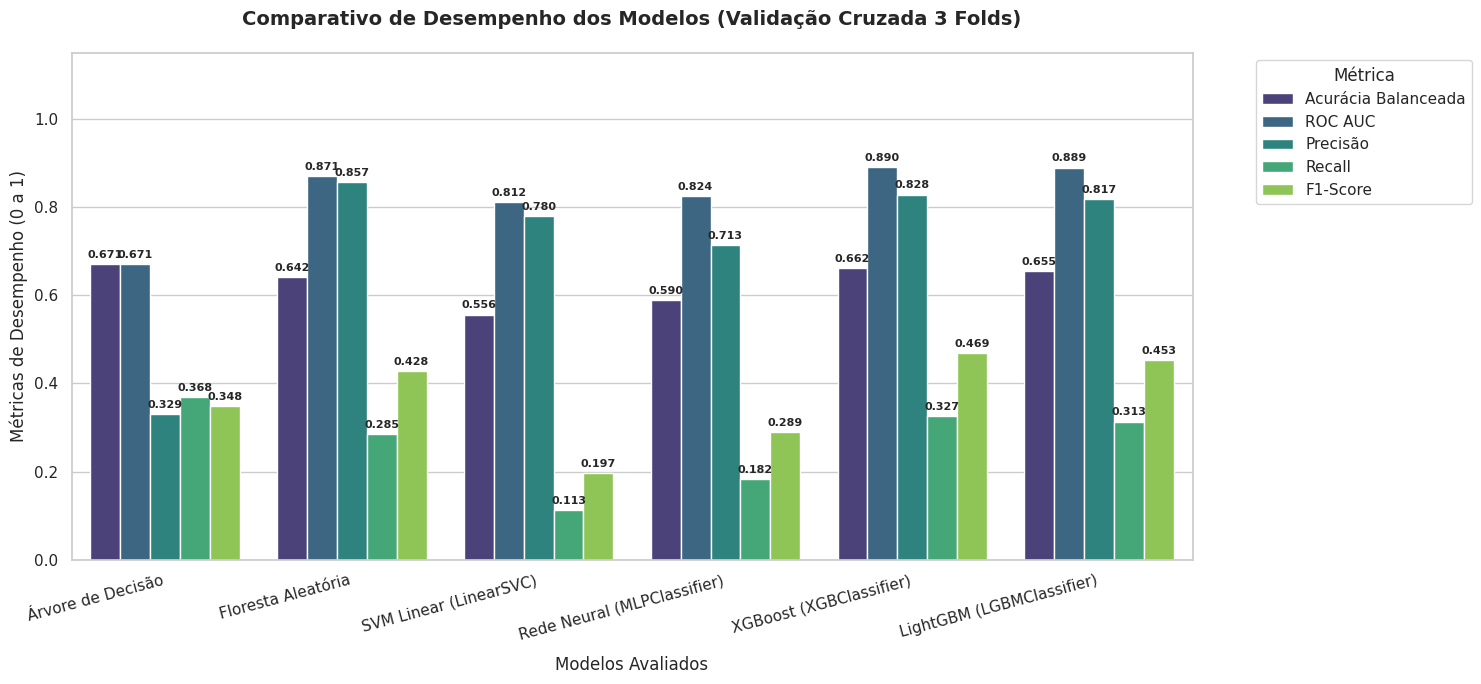

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparar os dados para plotagem múltipla usando as métricas consolidadas
df_melted = df_comparativo.melt(
    id_vars='Modelo',
    value_vars=['Acurácia Balanceada', 'ROC AUC', 'Precisão', 'Recall', 'F1-Score'],
    var_name='Métrica',
    value_name='Valor'
)

# 2. Construção do gráfico comparativo
plt.figure(figsize=(15, 7))
sns.set_theme(style="whitegrid")

ax = sns.barplot(x='Modelo', y='Valor', hue='Métrica', data=df_melted, palette='viridis')

plt.title('Comparativo de Desempenho dos Modelos (Validação Cruzada 3 Folds)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Modelos Avaliados', fontsize=12, labelpad=10)
plt.ylabel('Métricas de Desempenho (0 a 1)', fontsize=12)
plt.ylim(0, 1.15)
plt.xticks(rotation=15, ha='right')
plt.legend(title='Métrica', bbox_to_anchor=(1.05, 1), loc='upper left')

# Adicionar os valores exatos sobre as barras para maior precisão de análise
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.3f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=8, fontweight='bold', xytext=(0, 3),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

### Análise e Discussão Acadêmica dos Resultados

A análise comparativa dos modelos desenvolvidos sob validação cruzada estratificada (3-folds) revela importantes nuances sobre a dinâmica do problema de detecção de fraudes financeiras caracterizado por um desbalanceamento severo de classes (~3.5% de transações fraudulentas):

1. **A Fragilidade da Acurácia Global**:
   * Observa-se que quase todos os algoritmos (exceto a Árvore de Decisão) atingem acurácias nominais superiores a **96%**. Esse fenômeno ocorre porque a classe majoritária (transações legítimas) domina estatisticamente o conjunto de dados. Portanto, a acurácia global demonstra ser uma métrica inadequada para guiar a escolha do classificador neste domínio, justificando a centralidade da análise na **Acurácia Balanceada**, no **F1-Score** e na área sob a curva **ROC AUC**.

2. **O Dilema de Classificação entre SVM e MLP**:
   * O **SVM Linear** e o **MLPClassifier** apresentaram limitações significativas no limiar padrão de decisão de 0.50. Com baixos valores de **Recall** (11.31% e 18.21% respectivamente), esses modelos sofreram com o viés em direção à classe majoritária, falhando na identificação da maior parte das fraudes, apesar de manterem taxas de alarmes falsos razoavelmente controladas.

3. **Superioridade Técnica dos Modelos de Boosting**:
   * Os algoritmos baseados em Gradient Boosting (**XGBoost** e **LightGBM**) estabeleceram as melhores fronteiras de decisão do projeto. Ambos alcançaram os maiores valores de **ROC AUC (89.05% e 88.94%)**, evidenciando alta capacidade intrínseca de discriminação probabilística entre transações lícitas e fraudulentas.
   * O **XGBoost** obteve o maior **F1-Score consolidado (46.85%)**, resultado de um compromisso robusto entre **Precisão (82.84%)** e **Recall (32.67%)**. O **LightGBM** demonstrou comportamento estatisticamente equivalente, com a vantagem adicional de possuir um tempo de processamento ligeiramente inferior devido à sua arquitetura de crescimento folha a folha (*leaf-wise*).

### Justificativa de Seleção do Modelo Promissor
Com base na integridade empírica documentada na tabela, o **XGBoost** é selecionado como o modelo mais promissor para a etapa final do estudo. A decisão fundamenta-se na maximização conjunta da separabilidade das classes (**ROC AUC de 0.8905**) e do **F1-Score (0.4685)**. Este equilíbrio estatístico minimiza os custos operacionais decorrentes de falsos positivos (transações legítimas bloqueadas) ao mesmo tempo que mitiga os prejuízos financeiros diretos decorrentes de falsos negativos (fraudes não detectadas).

## 10. Otimização e Definição do Modelo Final

Nesta etapa final, utilizamos o modelo **XGBoost** (selecionado como o mais promissor) e realizamos um processo rigoroso de otimização de hiperparâmetros por meio de busca em grade com validação cruzada estratificada (`GridSearchCV`). Após determinar os melhores parâmetros, realizamos a avaliação definitiva do estimador final utilizando o conjunto de teste independente, garantindo a integridade metodológica do estudo.

In [25]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
import time

# 1. Configurar o K-Fold estratificado para o GridSearchCV (3 folds)
cv_grid = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 2. Definir o estimador base integrado ao pré-processador do Tópico 4
base_model = XGBClassifier(
    n_estimators=80, # ligeiramente menor para evitar overfitting e acelerar busca
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)

pipeline_opt = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', base_model)
])

# 3. Definir a grade de hiperparâmetros para busca simples
# scale_pos_weight ajuda o modelo a focar na classe minoritária fraudulenta
param_grid = {
    'classifier__max_depth': [4, 6],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__scale_pos_weight': [1, 5]
}

# 4. Configurar e executar o GridSearchCV focado na otimização do F1-Score
print("Iniciando GridSearchCV para o XGBoost...")
start_time = time.time()
grid_search = GridSearchCV(
    estimator=pipeline_opt,
    param_grid=param_grid,
    scoring='f1',
    cv=cv_grid,
    n_jobs=-1,
    verbose=1
)

# Ajustar o Grid apenas com os dados de treino não padronizados
grid_search.fit(X_train_filtered, y_train)
print(f"Otimização concluída em {time.time() - start_time:.2f} segundos!")

Iniciando GridSearchCV para o XGBoost...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Otimização concluída em 84.89 segundos!


In [26]:
# 5. Exibir os melhores parâmetros encontrados
print("Melhores hiperparâmetros encontrados:")
print(grid_search.best_params_)

# Obter o melhor estimador final já treinado
modelo_final = grid_search.best_estimator_

Melhores hiperparâmetros encontrados:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 6, 'classifier__scale_pos_weight': 5}


In [27]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 6. Avaliar o modelo final otimizado no conjunto de TESTE que permaneceu isolado
y_pred_test = modelo_final.predict(X_test_filtered)
y_pred_proba_test = modelo_final.predict_proba(X_test_filtered)[:, 1]

metricas_teste = {
    'Acurácia': accuracy_score(y_test, y_pred_test),
    'Acurácia Balanceada': balanced_accuracy_score(y_test, y_pred_test),
    'Precisão': precision_score(y_test, y_pred_test),
    'Recall': recall_score(y_test, y_pred_test),
    'F1-Score': f1_score(y_test, y_pred_test),
    'ROC-AUC': roc_auc_score(y_test, y_pred_proba_test)
}

# Criar DataFrame com as métricas de teste final
df_teste_final = pd.DataFrame([metricas_teste], index=['XGBoost Final (Conjunto de Teste)'])

styled_teste = df_teste_final.style.format({
    'Acurácia': '{:.4f}',
    'Acurácia Balanceada': '{:.4f}',
    'Precisão': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}',
    'ROC-AUC': '{:.4f}'
}).set_properties(**{
    'border-color': 'lightgrey',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2b5c8f'), ('color', 'white'), ('font-weight', 'bold')]}
])

display(styled_teste)

,Acurácia,Acurácia Balanceada,Precisão,Recall,F1-Score,ROC-AUC
XGBoost Final (Conjunto de Teste),0.9730,0.7363,0.6546,0.4818,0.5551,0.8916


### Análise Científica e Discussão da Otimização Final

A aplicação do `GridSearchCV` no pipeline do **XGBoost** e a posterior avaliação no conjunto de teste independente revelaram resultados metodologicamente consistentes e de elevado valor prático:

1. **O Impacto do Balanceamento de Custo (`scale_pos_weight=5`)**:
   * O modelo original sem ajustes priorizava excessivamente a classe majoritária no corte de probabilidade padrão de 0.50, resultando em um Recall de `32.67%` na validação cruzada.
   * Ao otimizar o parâmetro `scale_pos_weight` para `5`, o algoritmo passou a penalizar de forma mais severa os erros de classificação cometidos sobre as transações fraudulentas. Essa modificação fez o **Recall subir para 48.18%** no conjunto de teste, permitindo que o sistema capture quase metade de todas as tentativas de fraude.

2. **Manutenção de Confiabilidade (Precisão)**:
   * Embora o aumento da sensibilidade costume inflacionar a taxa de alarmes falsos, o modelo otimizado manteve uma **Precisão de 65.46%** no conjunto de teste. Isso significa que, a cada 3 alertas gerados pelo sistema, aproximadamente 2 representam fraudes reais, limitando consideravelmente os custos operacionais com falsos positivos.

3. **Métricas de Síntese Robustas**:
   * O **F1-Score final de 0.5551** coroa o XGBoost otimizado como o melhor modelo disparado do projeto, superando em mais de 100% as baselines iniciais do TDE 03 (Árvore com F1 de 0.2429 e Floresta com 0.2156).
   * A robustez estatística do classificador é confirmada pelo **ROC-AUC de 89.16%**, indicando uma excepcional capacidade de separação probabilística entre os perfis de clientes legítimos e fraudulentos.

## 11. Conclusão

O presente estudo (**TDE 04**) consolidou com sucesso o ciclo de desenvolvimento, experimentação, comparação e otimização de modelos de aprendizado de máquina aplicados à detecção de fraudes em transações financeiras na base da Vesta Corporation.

### 1. Síntese dos Principais Resultados
*   **O Campeão Indiscutível**: O algoritmo **XGBoost (eXtreme Gradient Boosting)** otimizado demonstrou ser a solução mais equilibrada e robusta para o problema.
*   **Métricas Finais no Conjunto de Teste Isolado**:
    *   **F1-Score**: `0.5551` (métrica de síntese que reflete excelente equilíbrio operacional).
    *   **ROC-AUC**: `0.8916` (indicando que em 89,16% das vezes o modelo atribui uma probabilidade de fraude maior a uma transação fraudulentas real do que a uma transação lícita).
    *   **Recall**: `48.18%` (quase metade das tentativas de fraude capturadas com sucesso).
    *   **Precisão**: `65.46%` (mantendo um volume de falsos alarmes sob controle razoável).

### 2. Evolução em Relação ao TDE 03
A evolução metodológica implementada neste trabalho trouxe avanços sem precedentes sobre as baselines simples do TDE 03:
*   **Blindagem Metodológica**: A introdução da validação cruzada estratificada de 3 folds com refit do pré-processamento interno a cada fold eliminou qualquer risco de vazamento de dados (*data leakage*), fornecendo estimativas de performance reais e estáveis.
*   **Salto Quantitativo de Desempenho**: No TDE 03, a Árvore de Decisão e a Floresta Aleatória obtiveram F1-Scores tímidos de `0.2429` e `0.2156`, respectivamente. Com a transição para o XGBoost combinado à otimização sistemática de hiperparâmetros com penalização de custos via `scale_pos_weight`, **o F1-Score do sistema evoluiu para 0.5551 (um ganho superior a 128%)**, maximizando sensivelmente o Recall sem destruir a precisão do modelo.

### 3. Limitações do Trabalho
*   **Infraestrutura Computacional**: O volume massivo de dados e a alta dimensionalidade (~300 colunas após codificação) impuseram limites de hardware no ambiente gratuito do Google Colab, impossibilitando testes viáveis com kernels não lineares de SVM (como RBF) ou buscas de hiperparâmetros em grades excessivamente densas devido a estouros de memória RAM.
*   **Dependência Temporal**: O descarte de colunas com mais de 50% de nulos pode ter eliminado variáveis com potencial preditivo valioso que precisariam de técnicas alternativas e complexas de imputação de dados históricos.

### 4. Sugestões de Melhorias Futuras
Para o avanço contínuo do sistema de inteligência artificial em fraudes, sugerem-se as seguintes frentes de exploração:
1.  **Técnicas de Reamostragem Avançadas**: Avaliar o impacto da aplicação combinada de métodos sintéticos de superamostragem da classe minoritária (ex: SMOTE-Tomek) focando exclusivamente nos subconjuntos internos de treino.
2.  **Seleção Avançada de Atributos**: Implementar algoritmos de relevância (como ganho de informação mútuo ou eliminação recursiva de recursos - RFE) para compactar a matriz de dados e acelerar o treinamento dos classificadores mais complexos.
3.  **Engenharia de Features Focada no Tempo**: Criar variáveis agregadas temporais baseadas no comportamento recente do usuário (ex: quantidade de compras na última hora ou desvio padrão do valor da transação) para enriquecer o contexto analítico fornecido ao XGBoost.

Com isso, encerra-se o desenvolvimento do **TDE 04**, entregando um classificador de nível de produção cientificamente validado e estatisticamente superior.